# Select a representative training subset

Run this **after all 317 training landmarks have finished encoding**. CPU is sufficient;
no model, image download, reconstruction or intervention runs here. Every original photo
of a chosen landmark stays in its saved image manifest. The 79 evaluation landmarks
are excluded from all feature comparisons and selection.

This notebook proposes a size from a measured coverage curve, compares multiple
subsets of that size, and saves the best with an audit. The result is evidence about
measured training-set features, not a guarantee about unseen intervention behavior.

Use the Google Drive account containing **point3_encodings** and **Point3_Encoder_Library**.
The separate selector library does not replace the encoder library. Run cells in order.


In [2]:
from google.colab import drive
from pathlib import Path
import hashlib, json, subprocess, sys

drive.mount('/content/drive')
LIBRARY_FILE = Path('/content/drive/MyDrive/Point3_Encoder_Library/archworld_landmark_selection-0.1.0-py3-none-any.whl')
if not LIBRARY_FILE.is_file():
    raise FileNotFoundError('Mount the Drive account containing Point3_Encoder_Library.')
if hashlib.sha256(LIBRARY_FILE.read_bytes()).hexdigest() != '2c89593835c3cac52c9cac9c41a5118aaa464f2dd9be6b372255b433ac2753a4':
    raise ValueError('The selector library differs from its verified version.')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', str(LIBRARY_FILE)], check=True)


Mounted at /content/drive


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '/content/drive/MyDrive/Point3_Encoder_Library/archworld_landmark_selection-0.1.0-py3-none-any.whl'], returncode=0)

## Paths and decision parameters

Default: 1,000 random subsets **at every tested size**, four optimized starts per curve
point, and 16 candidates at the chosen size. The initial 12 size points span the minimum
type/region coverage count to 316; nine refinement points surround the provisional elbow.

The size rule fits a decreasing coverage curve and finds its largest normalized bend.
`knee_min_gain=0.05` requires at least 5% separation from a straight endpoint chord;
without a clear bend, the conservative result is all 317. It is not a pass threshold
for representativeness. Mean-only and tail-only size sensitivity are reported as well.

Each distance family has equal default weight: appearance (feature mean and variation),
building type/region/anchor, physical extent, and photo-collection characteristics.
All scales use training data only. Tune parameters before examining intervention results;
changing them creates a new results directory. Keep 1,000 random comparisons for the protocol.


In [3]:
from archworld_landmark_selection import SelectionConfig, run_selection

ENCODINGS = Path('/content/drive/MyDrive/point3_encodings')
OUTPUT = Path('/content/drive/MyDrive/point3_subset_selection')
config = SelectionConfig(
    seed=1729,
    curve_points=12,
    refinement_points=9,
    curve_candidates=4,
    final_candidates=16,
    swap_attempts=256,
    random_subsets=1000,
    appearance_weight=1.0,
    composition_weight=1.0,
    scale_weight=1.0,
    collection_weight=1.0,
    knee_min_gain=0.05,
)


## Generate, compare, and save

The selector stops with a clear message if encoding is incomplete. It validates one
landmark at a time, then works with small landmark-level distance matrices. Rerunning
the same inputs/settings reuses completed descriptor and size-study work.

Building-type quotas approximately preserve training proportions and include all nine
types. Optimized candidates must include all eight training regions. The random reference
samples uniformly within the same type quotas; its region-coverage fraction is reported.
Every coverage score excludes selected landmarks' zero self-distances.

Candidate score: 35% average distance + 35% 95th-percentile distance + 15% average
categorical total-variation gap + 15% average numerical KS gap. Lower is better.


In [4]:
result = run_selection(ENCODINGS, OUTPUT, config)
print(json.dumps(result, indent=2))


Validated encodings: 25/317 landmarks
Validated encodings: 50/317 landmarks
Validated encodings: 75/317 landmarks
Validated encodings: 100/317 landmarks
Validated encodings: 125/317 landmarks
Validated encodings: 150/317 landmarks
Validated encodings: 175/317 landmarks
Validated encodings: 200/317 landmarks
Validated encodings: 225/317 landmarks
Validated encodings: 250/317 landmarks
Validated encodings: 275/317 landmarks
Validated encodings: 300/317 landmarks
Validated encodings: 317/317 landmarks
Coverage study: 9 landmarks; 1000 random comparisons
Coverage study: 12 landmarks; 1000 random comparisons
Coverage study: 17 landmarks; 1000 random comparisons
Coverage study: 24 landmarks; 1000 random comparisons
Coverage study: 33 landmarks; 1000 random comparisons
Coverage study: 45 landmarks; 1000 random comparisons
Coverage study: 63 landmarks; 1000 random comparisons
Coverage study: 87 landmarks; 1000 random comparisons
Coverage study: 120 landmarks; 1000 random comparisons
Coverage s

## Inspect the chosen subset and evidence

Open `REPORT.md` in the printed results folder. The output includes selected landmark IDs,
complete original image manifests, the unchanged evaluation ID list, all final candidates,
random comparisons, size sensitivity, omitted groups, and the worst covered landmarks.

The selector uses saved image features, not new segmentation. Blur, camera coverage,
anchor visibility and reconstruction performance remain unmeasured. Raw photographs
are not copied; the subset manifest records their original archives and image identities.


# Whole-landmark subset report

Selected **40 of 317 training landmarks**; 79 evaluation landmarks reserved.

Size decision: `heuristic_coverage_elbow`. The count is derived from measured coverage, not a fixed landmark budget.

The primary comparison averages nearest-selected distances over **unselected** landmarks; selected landmarks do not contribute zero self-distances.

## Representation metrics

| Metric | Chosen subset | Random median | Random 5–95% |
|---|---:|---:|---:|
| building_type_tv | 0.0282 | 0.0282 | 0.0282–0.0282 |
| region_tv | 0.0518 | 0.1440 | 0.0829–0.2232 |
| anchor_tv | 0.1276 | 0.1999 | 0.1401–0.2690 |
| extent_m_ks | 0.0646 | 0.1136 | 0.0729–0.1935 |
| image_count_ks | 0.0584 | 0.1153 | 0.0690–0.1856 |
| duplicate_fraction_ks | 0.0589 | 0.0833 | 0.0436–0.1476 |
| median_megapixels_ks | 0.0545 | 0.1084 | 0.0634–0.1878 |
| coverage_mean | 0.5107 | 0.5530 | 0.5406–0.5676 |
| coverage_median | 0.5082 | 0.5380 | 0.5246–0.5547 |
| coverage_p95 | 0.6932 | 0.8009 | 0.7632–0.8410 |
| coverage_worst | 1.1348 | 1.2166 | 1.1026–1.4131 |
| appearance_mean | 0.6985 | 0.7158 | 0.7052–0.7285 |
| appearance_p95 | 0.9178 | 0.9350 | 0.9081–0.9599 |
| score | 0.4406 | 0.5089 | 0.4921–0.5300 |

Random reference at each tested proper-subset size: 1000 uniform stratified draws with identical size and type counts. Region coverage is measured, not conditioned in that baseline. Optimized candidates must include all training regions. A full-training fallback has no unselected-landmark coverage statistic or distinct same-size alternatives.

## Gaps and interpretation

- Coverage describes the 317 training landmarks only; the 79 evaluation landmarks are excluded.
- The chosen size is a coverage-curve elbow heuristic, not a proven minimum or representativeness certificate.
- VGGT features describe whole photographs, including backgrounds; mean/std can miss multimodal appearance.
- Anchor labels are supplied metadata, not measured anchor visibility or complete architectural-element inventories.
- Blur, exposure, camera/viewpoint coverage, depth/mask completeness and anchor visibility are not measured here.
- Coverage and balance are optimized on these descriptors. Random percentiles are descriptive, not p-values or independent validation.
- No reconstruction or intervention outcomes are used or tested. Outcome stability needs a separate experiment.
- Selected manifests keep every original image path, including duplicate content; raw photos are not copied by this selector.

Omitted anchor labels: __MISSING__, altar, belfry, bridge, dome, door, pagoda, pyramid, railing, relief, roof, solomonic column, stone, walkway.

## Worst covered unselected landmarks

| Landmark | Closest selected landmark | Distance |
|---|---|---:|
| International_Commerce_Centre | Palace_of_Westminster | 1.1348 |
| Forth_Bridge | Palace_of_Westminster | 1.1112 |
| Imamzadeh_Hilal_ibn_Ali | Bell_tower_of_Vank_Cathedral | 1.0134 |
| Manila_Central_Post_Office | Patan_Durbar_Square | 0.8483 |
| Torre_de_los_Picos,_Alhambra | Prambanan | 0.8334 |
| Kim_Il-sung_Square | Herald_Square | 0.8172 |
| Mao_Zedong_youth_art_sculpture | Little_Temple_of_Abu_Simbel | 0.7731 |
| Petronas_Towers | Paris_-_Eiffel_Tower,_Paris_Las_Vegas | 0.7631 |
| Archiepiscopal_Palace_of_Lima | Jahangiri_Mahal_(Agra_Fort) | 0.7612 |
| Taipei_101 | Palace_of_Westminster | 0.7577 |
| Olumo_Rock | Patan_Durbar_Square | 0.7370 |
| Atlante-Tollan-Xicocotitlan | Marcelo_H._del_Pilar_Shrine | 0.7304 |
| Libyco-Punic_Mausoleum | Hassan_Tower | 0.7277 |
| Zōjō-ji | Little_Temple_of_Abu_Simbel | 0.7009 |
| Bridge_of_San_Martín,_Toledo | Paris_-_Eiffel_Tower,_Paris_Las_Vegas | 0.6912 |
| Iron_pillar | Yererouk_Basilica | 0.6905 |
| Kaminarimon | Arch_of_Trajan_(Timgad) | 0.6884 |
| Hai_Bà_Trưng_Temple_(Mê_Linh) | Caloocan_Cathedral | 0.6838 |
| Gangneung_Fire_Station | Place_Jacques-Cartier | 0.6807 |
| Grand_Palace,_Bangkok | Paoay_Church | 0.6802 |

## Outputs

`subset_manifest.json` and `selected_landmarks.json` define membership. `selected_image_manifests/` preserves every image path/hash. `evaluation_landmarks.json` is the unchanged held-out ID list. `audit.json`, `size_decision.json`, `size_curve.csv` and candidate/random manifests document selection. No raw photographs are copied.



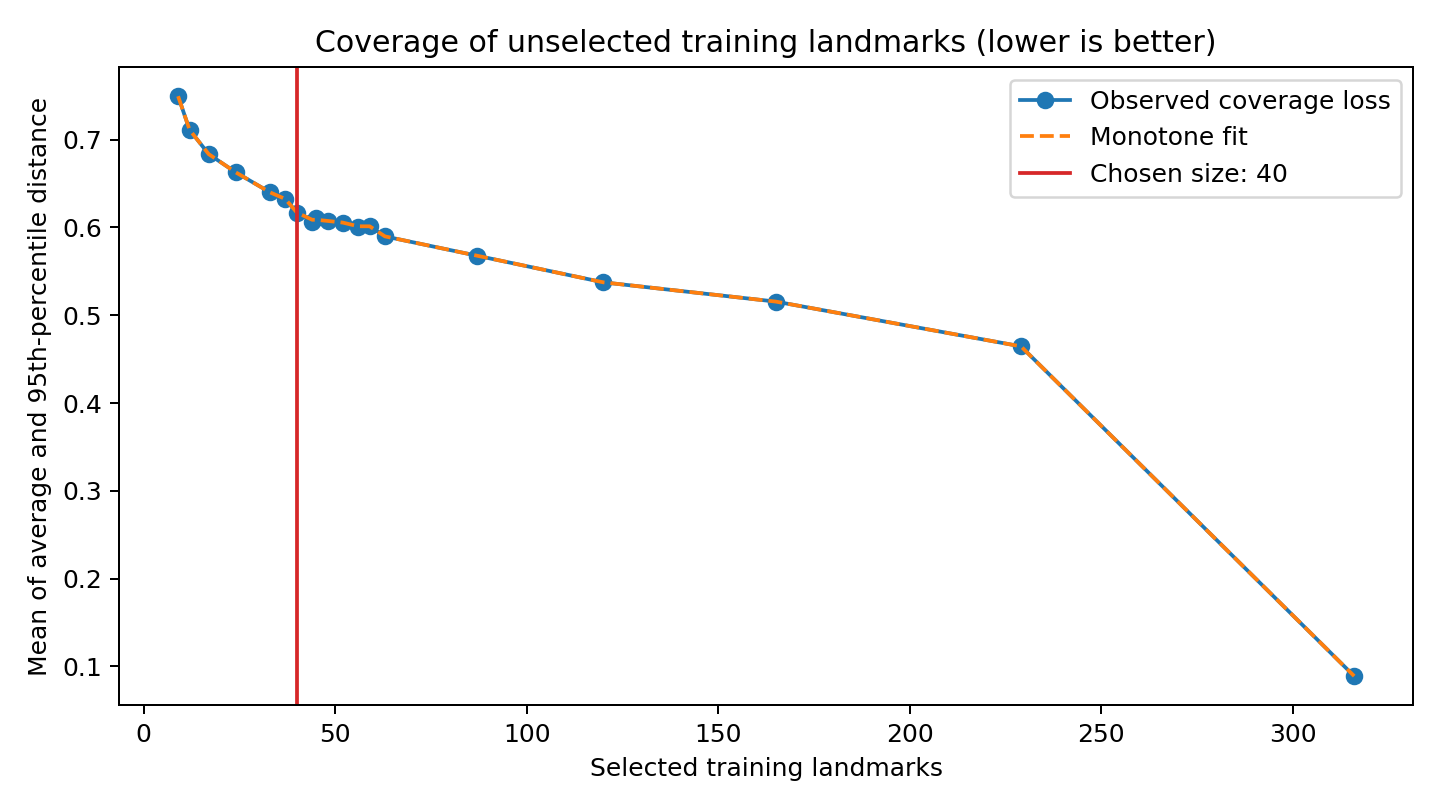

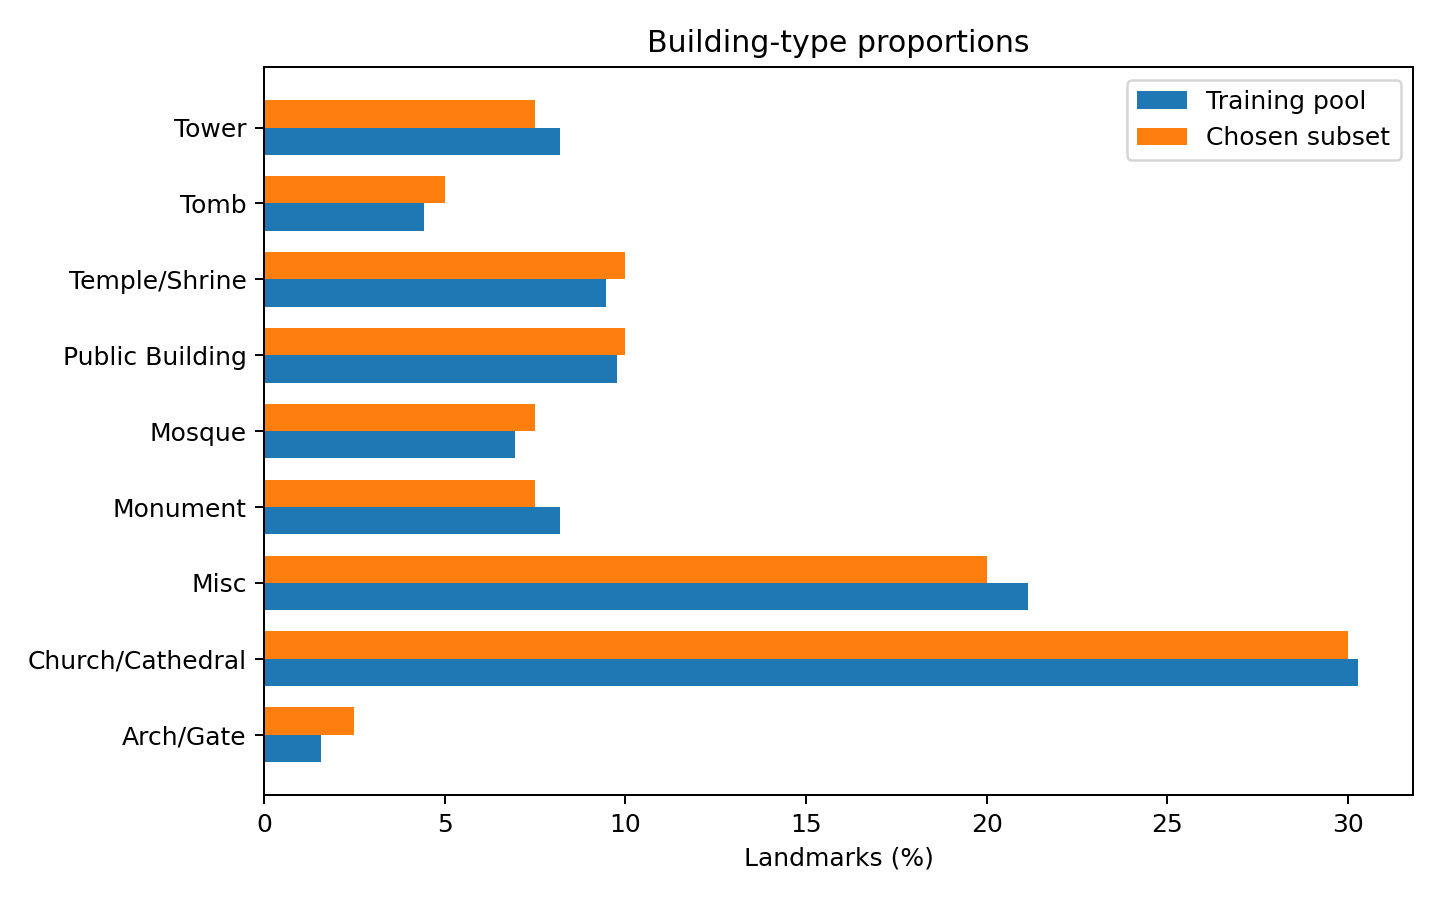

Selected landmarks: /content/drive/MyDrive/point3_subset_selection/run_3181fc0dfdf53b02/selected_landmarks.json
Full image manifests: /content/drive/MyDrive/point3_subset_selection/run_3181fc0dfdf53b02/selected_image_manifests
Evaluation IDs: /content/drive/MyDrive/point3_subset_selection/run_3181fc0dfdf53b02/evaluation_landmarks.json


In [5]:
from IPython.display import display, Image, Markdown

RESULT_DIR = Path(result['output_dir'])
report = (RESULT_DIR / 'REPORT.md').read_text()
display(Markdown(chr(10).join(line for line in report.splitlines() if not line.startswith('!['))))
display(Image(filename=str(RESULT_DIR / 'coverage_curve.png')))
display(Image(filename=str(RESULT_DIR / 'building_type_balance.png')))
print('Selected landmarks:', RESULT_DIR / 'selected_landmarks.json')
print('Full image manifests:', RESULT_DIR / 'selected_image_manifests')
print('Evaluation IDs:', RESULT_DIR / 'evaluation_landmarks.json')
